In [24]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
from matplotlib import cm

In [50]:
# cleaning a booth fuction method
def booth_function(x,y):
    return (x + 2*y)**2 + (2*x + y - 5)**2
    

Text(0.5, 0.92, 'Booth Function')

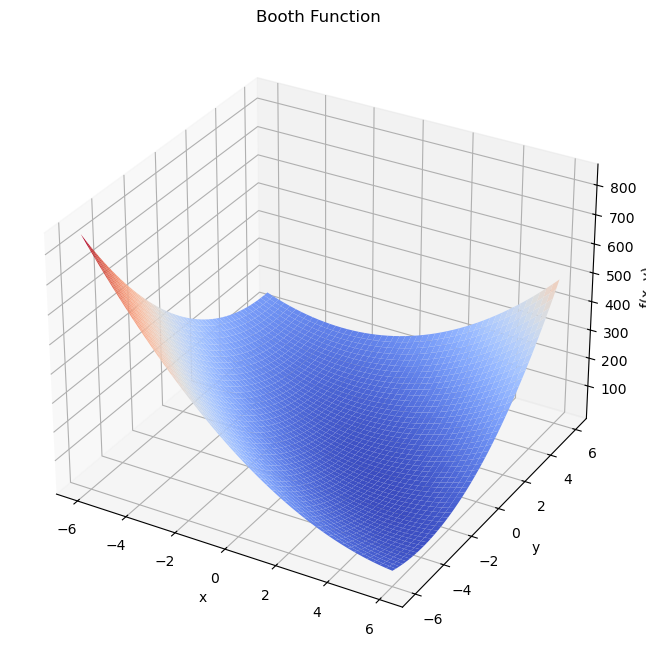

In [26]:
# Data for a three-dimensional line
x = np.linspace(-6, 6, 50)
y = np.linspace(-6, 6, 50)
xline, yline = np.meshgrid(x,y)
z = booth_function(xline, yline)

fig = plt.figure(figsize =[12, 8])
ax = plt.axes(projection='3d')
ax.plot_surface(xline,yline,z, cmap = cm.coolwarm)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x, y)")
ax.set_title('Booth Function')


In [27]:
# Derivative of booth functions
def partial_derivative_x(x, y):
    return 2 * (x + 2 * y) + 4 * (2 * x + y - 5)

def partial_derivative_y(x, y):
    return 4 * (x + 2 * y) + 2 * (2 * x + y - 5)


In [28]:
# Gradient Descent initialization
alpha = 0.01  # Learning rate
initial_x, initial_y = -1, 1  # Initial guess
tolerance = 1e-6  # Tolerance for stopping condition
max_iters = 1000  # Maximum number of iterations

x, y = initial_x, initial_y
path_x, path_y = [x], [y]  # Store the path for plotting

#loop for gradient descent
for i in range(max_iters):
    # Compute the gradient
    dfdx = partial_derivative_x(x, y)
    dfdy = partial_derivative_y(x, y)
    
    # Update x and y
    x_new = x - alpha * dfdx
    y_new = y - alpha * dfdy
    
    # Check for convergence
    if abs(x_new - x) < tolerance and abs(y_new - y) < tolerance:
        print(f"Converged after {i} iterations.")
        break
    
    # Update variables for next iteration
    x, y = x_new, y_new
    #appending each x and y for path so that it is plotted well
    path_x.append(x)
    path_y.append(y)


Converged after 553 iterations.


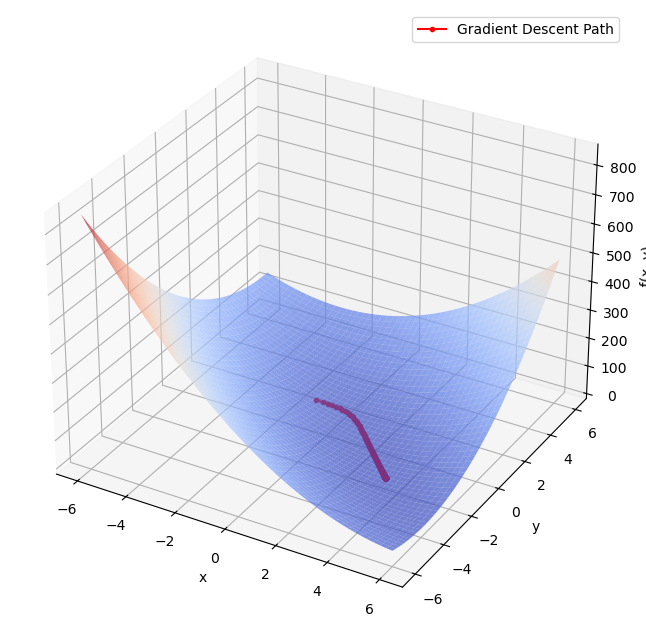

In [29]:
fig = plt.figure(figsize =[12, 8])
ax = plt.axes(projection='3d')
ax.plot_surface(xline,yline,z,cmap = cm.coolwarm, alpha=0.7)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x, y)")

# Calculate the function values along the path for plotting
path_z = booth_function(np.array(path_x), np.array(path_y))

# Plot the gradient descent path
ax.plot(path_x, path_y, path_z, color='r', marker='o', markersize=3, label="Gradient Descent Path")
ax.legend()

plt.show()

In [56]:
def backtracking_line_search(x, y, dfdx, dfdy, alpha=1.0, beta=0.5, gamma=0.5):
    while True:
        # Check the Armijo condition (sufficient decrease condition)
        new_x = x - alpha * dfdx
        new_y = y - alpha * dfdy
        if booth_function(new_x, new_y) <= booth_function(x, y) - gamma * alpha * (dfdx**2 + dfdy**2):
            break  # Accept the step size
        alpha *= beta  # Reduce the step size
    return alpha
              
# Initialize starting point
x, y = initial_x, initial_y

# Gradient Descent Loop with Backtracking Line Search
for i in range(max_iters):
    # Compute the gradient at the current point
    dfdx = partial_derivative_x(x, y)
    dfdy = partial_derivative_y(x, y)
    
    # Determine adaptive step size using backtracking line search
    alpha = backtracking_line_search(x, y, dfdx, dfdy)
    
    # Update x and y based on the gradient and adaptive learning rate
    x_new = x - alpha * dfdx
    y_new = y - alpha * dfdy
    
    # Check for convergence: stop if updates are smaller than the tolerance
    if abs(x_new - x) < tolerance and abs(y_new - y) < tolerance:
        print(f"Converged after {i+1} iterations.")
        break
    
    # Update current values of x and y for the next iteration
    x, y = x_new, y_new

# If the loop completes without convergence
else:
    print("Gradient descent did not converge within the maximum number of iterations.")


Converged after 37 iterations.


In [31]:
#loading the data and viewing the first 5 rows
data = pd.read_csv('regression.csv')
data.head(5)

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,Y
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [6]:
#checking for any missing values
data.isnull().sum()

X1     0
X2     0
X3     0
X4     0
X5     0
X6     0
X7     0
X8     0
X9     0
X10    0
X11    0
Y      0
dtype: int64

In [7]:
data.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,Y
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [8]:
data.shape

(1599, 12)

In [9]:
#Train to Test split should be 80-20.
# Shuffle and split the DataFrame
train_data = data.sample(frac=0.8, random_state=42)  # 80% for training
test_data = data.drop(train_data.index)  # Remaining 20% for testing

In [18]:
#normalization of data
def standard_scaler(x_data, X_column):
    mean = np.mean(X_column)
    std_dev = np.std(X_column)
    z = (x_data - mean) / std_dev
    return z

In [19]:

#creating a new data empty datafarne to store the standardized data
train_data_standardized = pd.DataFrame()

for column in train_data.columns:
    train_data_standardized[column] = standard_scaler(train_data[column].values ,train_data[column] )


In [20]:
test_data_standardized = pd.DataFrame()

for column in test_data.columns:
    test_data_standardized[column] = standard_scaler(test_data[column].values ,test_data[column] )

In [57]:
import numpy as np

# Optimization class to implement different optimization methods
class Optimization:
    def __init__(self, X, y):
        self.X = X
        self.y = y
        self.loss = Loss(X, y)  # Instantiate the Loss class
    
    # Newton's Method Optimization
    def newtons_method(self, initial_w, max_iters=1000, tolerance=1e-6):

        w = initial_w
        
        for i in range(max_iters):
            # Compute the gradient and Hessian matrix for the loss function
            gradient = self.loss.cross_entropy_loss_gradient(w)  # Gradient of the loss
            hessian = self.hessian_matrix(w)  # Hessian matrix of the loss function

            # Update the weights using Newton's method
            w_new = w - np.linalg.inv(hessian).dot(gradient)
            
            # Check for convergence
            if np.linalg.norm(w_new - w) < tolerance:
                print(f"Converged after {i+1} iterations.")
                break
            
            # Update the weights for the next iteration
            w = w_new

        return w

    # Hessian matrix for the loss function (Second derivative)
    def hessian_matrix(self, w):
        
        predictions = self.loss.sigmoid(np.dot(self.X, w))
        H = np.dot(self.X.T, self.X * predictions * (1 - predictions)) / len(self.y)
        return H


In [58]:
# Loss class to handle different loss functions and their gradients
class Loss:
    def __init__(self, X, y):
        self.X = X
        self.y = y
        
    # Mean Squared Loss (MSE)
    def mean_squared_loss(self, w):
        predictions = np.dot(self.X, w)
        loss = np.mean((predictions - self.y) ** 2)
        return loss

    # Gradient of Mean Squared Loss
    def mean_squared_loss_gradient(self, w):
        predictions = np.dot(self.X, w)
        gradient = 2 * np.dot(self.X.T, (predictions - self.y)) / len(self.y)
        return gradient
    
    # Cross-Entropy Loss (Logistic Loss)
    def cross_entropy_loss(self, w):
    
        predictions = self.sigmoid(np.dot(self.X, w))
        loss = -np.mean(self.y * np.log(predictions + 1e-8) + (1 - self.y) * np.log(1 - predictions + 1e-8))
        return loss

    # Gradient of Cross-Entropy Loss
    def cross_entropy_loss_gradient(self, w):
        predictions = self.sigmoid(np.dot(self.X, w))
        gradient = np.dot(self.X.T, (predictions - self.y)) / len(self.y)
        return gradient

    # Sigmoid function for logistic regression
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
